$\textbf{Part e}$

In [1]:
import numpy as np
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import time                    
import optax
import matplotlib.pyplot as plt
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score,
                             classification_report,
                             roc_curve as sk_roc_curve, roc_auc_score, RocCurveDisplay)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (KFold, StratifiedKFold, cross_val_score, cross_validate,
                                     cross_val_predict, GridSearchCV, validation_curve, learning_curve)

from neural_network import (NeuralNetwork, EstimatorClassifier, sigmoid, sigmoid_der, ReLU, ReLU_der, softmax,
                            cross_entropy, smce_der, plot_classification)

rs = 2026

Load in, flatten, scale, and split the dataset:

In [2]:
with np.load("mnist.npz") as data:
    x_train, y_train = data["x_train"], data["y_train"]
    x_test, y_test = data["x_test"], data["y_test"]

x_train = x_train.reshape(len(x_train), -1) / 255.0
x_test = x_test.reshape(len(x_test), -1) / 255.0

First baseline: guess only most frequent number:

In [3]:
digits, counts = np.unique(y_test, return_counts = True)
print(digits[np.argmax(counts)])
print(np.max(counts) / len(y_test))

1
0.1135


Baseline: logistic regression

In [4]:
"""
model = LogisticRegression(solver = "lbfgs", max_iter = 1000, random_state = rs)
model.fit(x_train, y_train)
"""

'\nmodel = LogisticRegression(solver = "lbfgs", max_iter = 1000, random_state = rs)\nmodel.fit(x_train, y_train)\n'

In [5]:
"""
y_tilde = model.predict(x_test)
accuracy = accuracy_score(y_test, y_tilde)
print(np.round(accuracy, 4))
"""

'\ny_tilde = model.predict(x_test)\naccuracy = accuracy_score(y_test, y_tilde)\nprint(np.round(accuracy, 4))\n'

Cross validation setup:

In [6]:
rng = np.random.default_rng(rs)
k = 5
sub = np.concatenate([rng.choice(np.where(y_train == c)[0], 1000, replace=False) for c in range(10)])
sub = rng.permutation(sub)                                  # random order, so that the first m of any fold are a mixture
X_sub, y_sub = x_train[sub], y_train[sub]
cv_strat = StratifiedKFold(n_splits = k, shuffle=True, random_state = rs)

Gridsearch over learning rates and architecture. Epochs = 10, and no regularisation:

In [7]:
hiddens_c = [32, 64, 128]
gammas_c = [0.01, 0.03, 0.1]
t0 = time.time()
search_c = GridSearchCV(EstimatorClassifier(), {"hidden": hiddens_c, "gamma": gammas_c},
                        cv=cv_strat, scoring= "accuracy", return_train_score=True)

search_c.fit(X_sub, y_sub)
print(f"{len(hiddens_c) * len(gammas_c) * k} training runs in {time.time() - t0:.0f} s")


rc = search_c.cv_results_
shape_c = (len(gammas_c), len(hiddens_c))                    # 'gamma' is first in alphabetical order, so it is the outer loop
acc_c = rc["mean_test_score"].reshape(shape_c)
se_c = rc["std_test_score"].reshape(shape_c) / np.sqrt(k - 1)

"""
tr_c = rc["mean_train_score"].reshape(shape_c)
ib = np.unravel_index(np.argmax(acc_c), shape_c)
within_c = acc_c >= acc_c[ib] - se_c[ib]
print(f"{'gamma \\ hidden':>15s}" + "".join(f"{h:>22d}" for h in hiddens_c) + "      (CV accuracy +/- s.e., training accuracy in brackets)")
for i, g in enumerate(gammas_c):
    print(f"{g:>15g}" + "".join(f"{acc_c[i, j]:10.4f}+/-{se_c[i, j]:.4f}{'*' if within_c[i, j] else ' '}({tr_c[i, j]:.3f})" for j in range(shape_c[1])))
print(f"best: hidden {hiddens_c[ib[1]]}, gamma {gammas_c[ib[0]]:g}: {acc_c[ib]:.4f} +/- {se_c[ib]:.4f}; cells within one s.e. (*): {within_c.sum()}")
cands_c = [(i, j) for i in range(shape_c[0]) for j in range(shape_c[1]) if within_c[i, j]]
i1c, j1c = min(cands_c, key=lambda t: (hiddens_c[t[1]], -acc_c[t]))
print(f"one-standard-error rule towards the smaller network: hidden {hiddens_c[j1c]}, gamma {gammas_c[i1c]:g}: {acc_c[i1c, j1c]:.4f} +/- {se_c[i1c, j1c]:.4f}")
best_c = NeuralNetClassifier(hidden=(hiddens_c[j1c],), gamma=gammas_c[i1c], epochs=10)
"""

c:\Users\amund\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py:953: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "c:\Users\amund\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py", line 942, in _score
    scores = scorer(estimator, X_test, y_test, **score_params)
  File "c:\Users\amund\anaconda3\Lib\site-packages\sklearn\metrics\_scorer.py", line 308, in __call__
    return self._score(partial(_cached_call, None), estimator, X, y_true, **_kwargs)
           ~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\amund\anaconda3\Lib\site-packages\sklearn\metrics\_scorer.py", line 400, in _score
    y_pred = method_caller(
        estimator,
    ...<2 lines>...
        pos_label=pos_label,
    )
  File "c:\Users\amund\anaconda3\Lib\site-packages\sklearn\metrics\_scorer.py", line 90, in _cached_call
    r

45 training runs in 1663 s


'\ntr_c = rc["mean_train_score"].reshape(shape_c)\nib = np.unravel_index(np.argmax(acc_c), shape_c)\nwithin_c = acc_c >= acc_c[ib] - se_c[ib]\nprint(f"{\'gamma \\ hidden\':>15s}" + "".join(f"{h:>22d}" for h in hiddens_c) + "      (CV accuracy +/- s.e., training accuracy in brackets)")\nfor i, g in enumerate(gammas_c):\n    print(f"{g:>15g}" + "".join(f"{acc_c[i, j]:10.4f}+/-{se_c[i, j]:.4f}{\'*\' if within_c[i, j] else \' \'}({tr_c[i, j]:.3f})" for j in range(shape_c[1])))\nprint(f"best: hidden {hiddens_c[ib[1]]}, gamma {gammas_c[ib[0]]:g}: {acc_c[ib]:.4f} +/- {se_c[ib]:.4f}; cells within one s.e. (*): {within_c.sum()}")\ncands_c = [(i, j) for i in range(shape_c[0]) for j in range(shape_c[1]) if within_c[i, j]]\ni1c, j1c = min(cands_c, key=lambda t: (hiddens_c[t[1]], -acc_c[t]))\nprint(f"one-standard-error rule towards the smaller network: hidden {hiddens_c[j1c]}, gamma {gammas_c[i1c]:g}: {acc_c[i1c, j1c]:.4f} +/- {se_c[i1c, j1c]:.4f}")\nbest_c = NeuralNetClassifier(hidden=(hiddens_c[j

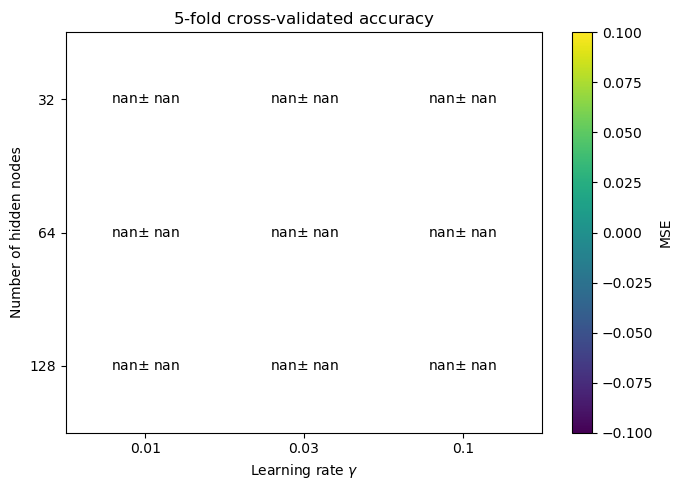

In [9]:
fig, ax = plt.subplots(figsize=(7, 5))
heatmap = ax.imshow(acc_c, cmap="viridis", aspect="auto")
ax.set_xticks(np.arange(len(gammas_c)))
ax.set_xticklabels([f"{value:g}" for value in gammas_c])
ax.set_yticks(np.arange(len(hiddens_c)))
ax.set_yticklabels([f"{value:g}" for value in hiddens_c])
ax.set_xlabel("Learning rate $\\gamma$")
ax.set_ylabel("Number of hidden nodes")
ax.set_title("$5$-fold cross-validated accuracy")


for row in range(acc_c.shape[0]):
    for col in range(acc_c.shape[1]):
        color = "black"
        ax.text(col, row, f"{acc_c[row, col]:.3g}$\\pm$ {se_c[row,col]:.3g}", ha="center", va="center", color=color)

fig.colorbar(heatmap, ax=ax, label="MSE")
fig.tight_layout()
plt.show()